[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcostac/generative-networks/blob/main/vae/hierarchical_vae.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Training a Hierarchical VAE on MNIST

Tutorial for training a small hierarchical Variational Autoencoder (VAE) to reconstruct and generate MNIST-like handwritten digits.

A standard VAE uses one latent variable `z`. A hierarchical VAE uses multiple latent variables, often arranged from coarse to fine information. In this notebook we use two levels:

- `z2` is the top latent variable. It has a standard normal prior and can learn broad digit structure.
- `z1` is the lower latent variable. Its prior is conditioned on `z2`, so it can learn details that depend on the top-level code.

The decoder generates images from `z1`, while `z2` shapes the distribution that `z1` comes from.

## 0. Dependencies

In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

The defaults are close to the basic VAE notebook, with separate sizes for the two latent levels. Increase `epochs` if you want cleaner generated samples.

In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "vae" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "vae" / "outputs" / "mnist_hierarchical_vae"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
image_channels = 1
image_size = 28
image_dim = image_channels * image_size * image_size
hidden_dim = 400
levels = 2
lower_latent_dim = 20
top_latent_dim = 10
if levels < 1:
    raise ValueError("levels must be at least 1")
latent_dims = [lower_latent_dim] * (levels - 1) + [top_latent_dim]  # bottom -> top
epochs = 20
learning_rate = 1e-3

sample_every_epochs = 5
checkpoint_path = output_dir / "mnist_hierarchical_vae_checkpoint.pt"

## 3. Load MNIST

As in the basic VAE, we keep MNIST pixel values in `[0, 1]` and train with `binary_cross_entropy_with_logits`.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), # Convert PIL image to tensor and scale pixel values to [0, 1].
])

train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

len(train_dataset), len(train_loader), len(test_dataset), len(test_loader)

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(60000, 469, 10000, 79)

Let's inspect a batch of real MNIST images.

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


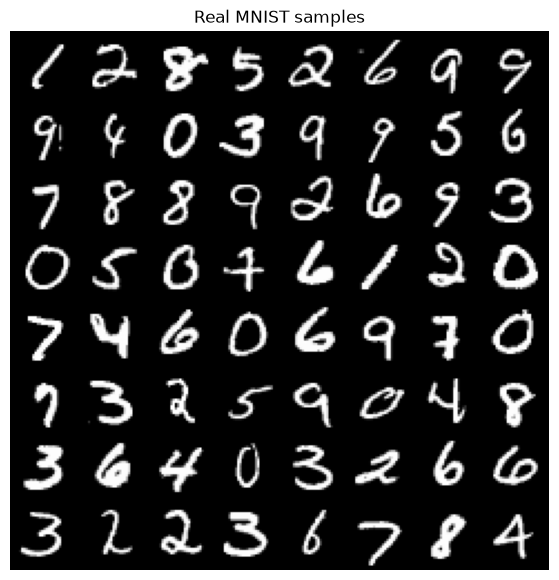

In [5]:
def show_image_grid(images, title=None, nrow=8):
    images = images.detach().cpu().clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


real_images, real_labels = next(iter(train_loader))
show_image_grid(real_images[:64], title="Real MNIST samples")

## 4. The Hierarchical Model

This notebook uses a simple two-level hierarchy by setting `levels = 2`:

`p(z2) = N(0, I)`

`p(z1 | z2) = N(mu_prior(z2), sigma_prior(z2))`

`p(x | z1)` is represented by Bernoulli logits from the decoder.

The implementation below is written with loops and `nn.ModuleList`, so the same class can support more levels by changing `levels`. The `latent_dims` list is generated automatically from `lower_latent_dim` and `top_latent_dim`.

The encoder approximates the posterior with one distribution per level. The top latent is inferred from the image features, then each lower latent is inferred from the image features and the sampled latent above it.

In [6]:
class HierarchicalVAE(nn.Module):
    def __init__(
        self,
        image_dim=784,
        hidden_dim=400,
        levels=2,
        lower_latent_dim=20,
        top_latent_dim=10,
        latent_dims=None,
        image_channels=1,
        image_size=28,
    ):
        super().__init__()
        if latent_dims is None:
            if levels < 1:
                raise ValueError("levels must be at least 1")
            latent_dims = [lower_latent_dim] * (levels - 1) + [top_latent_dim]
        elif levels != len(latent_dims):
            raise ValueError("levels must match len(latent_dims)")
        if len(latent_dims) < 1:
            raise ValueError("latent_dims must contain at least one latent level")

        self.image_channels = image_channels
        self.image_size = image_size
        self.latent_dims = list(latent_dims)
        self.levels = len(self.latent_dims)
        self.bottom_latent_dim = self.latent_dims[0]
        self.top_latent_dim = self.latent_dims[-1]

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(image_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(inplace=True),
        )

        self.q_hidden = nn.ModuleList()
        self.q_mu = nn.ModuleList()
        self.q_logvar = nn.ModuleList()
        for level, latent_dim in enumerate(self.latent_dims):
            if level == self.levels - 1:
                self.q_hidden.append(nn.Identity())
            else:
                upper_dim = self.latent_dims[level + 1]
                self.q_hidden.append(
                    nn.Sequential(
                        nn.Linear(hidden_dim + upper_dim, hidden_dim),
                        nn.ReLU(inplace=True),
                    )
                )
            self.q_mu.append(nn.Linear(hidden_dim, latent_dim))
            self.q_logvar.append(nn.Linear(hidden_dim, latent_dim))

        self.p_hidden = nn.ModuleList()
        self.p_mu = nn.ModuleList()
        self.p_logvar = nn.ModuleList()
        for level in range(self.levels - 1):
            upper_dim = self.latent_dims[level + 1]
            latent_dim = self.latent_dims[level]
            self.p_hidden.append(
                nn.Sequential(
                    nn.Linear(upper_dim, hidden_dim),
                    nn.ReLU(inplace=True),
                )
            )
            self.p_mu.append(nn.Linear(hidden_dim, latent_dim))
            self.p_logvar.append(nn.Linear(hidden_dim, latent_dim))

        self.decoder = nn.Sequential(
            nn.Linear(self.latent_dims[0], hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, image_dim),
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def encode(self, images):
        features = self.encoder(images)
        latents = [None] * self.levels
        mus = [None] * self.levels
        logvars = [None] * self.levels

        for level in reversed(range(self.levels)):
            if level == self.levels - 1:
                hidden = self.q_hidden[level](features)
            else:
                hidden = self.q_hidden[level](torch.cat([features, latents[level + 1]], dim=1))

            mus[level] = self.q_mu[level](hidden)
            logvars[level] = self.q_logvar[level](hidden)
            latents[level] = self.reparameterize(mus[level], logvars[level])

        return latents, mus, logvars

    def conditional_prior(self, level, upper_latent):
        hidden = self.p_hidden[level](upper_latent)
        return self.p_mu[level](hidden), self.p_logvar[level](hidden)

    def decode(self, z_bottom):
        logits = self.decoder(z_bottom)
        return logits.view(z_bottom.size(0), self.image_channels, self.image_size, self.image_size)

    def sample(self, num_samples):
        device = next(self.parameters()).device
        latents = [None] * self.levels
        top_level = self.levels - 1
        latents[top_level] = torch.randn(num_samples, self.latent_dims[top_level], device=device)

        for level in reversed(range(top_level)):
            prior_mu, prior_logvar = self.conditional_prior(level, latents[level + 1])
            latents[level] = self.reparameterize(prior_mu, prior_logvar)

        return self.decode(latents[0])

    def forward(self, images):
        latents, mus, logvars = self.encode(images)
        prior_mus = [None] * self.levels
        prior_logvars = [None] * self.levels

        for level in range(self.levels - 1):
            prior_mus[level], prior_logvars[level] = self.conditional_prior(level, latents[level + 1])

        reconstruction_logits = self.decode(latents[0])
        return {
            "reconstruction_logits": reconstruction_logits,
            "latents": latents,
            "mu": mus,
            "logvar": logvars,
            "prior_mu": prior_mus,
            "prior_logvar": prior_logvars,
        }

## 5. Define the Hierarchical VAE Objective

The loss still has one reconstruction term, but now it has two KL terms:

- `KL z2`: compares `q(z2 | x)` to the standard normal prior `p(z2)`.
- `KL z1`: compares `q(z1 | x, z2)` to the learned conditional prior `p(z1 | z2)`.

The second KL is the key hierarchical part: the lower-level latent variable is regularized against a distribution predicted from the upper-level latent variable.

In [7]:
def kl_to_standard_normal(mu, logvar):
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())


def kl_between_diagonal_gaussians(q_mu, q_logvar, p_mu, p_logvar):
    q_var = q_logvar.exp()
    p_var = p_logvar.exp()
    kl_per_dim = p_logvar - q_logvar + (q_var + (q_mu - p_mu).pow(2)) / p_var - 1
    return 0.5 * torch.sum(kl_per_dim)


def hierarchical_vae_loss(outputs, images):
    reconstruction_loss = F.binary_cross_entropy_with_logits(
        outputs["reconstruction_logits"],
        images,
        reduction="sum",
    )

    kl_terms = []
    top_level = len(outputs["mu"]) - 1
    for level in range(top_level + 1):
        if level == top_level:
            kl = kl_to_standard_normal(outputs["mu"][level], outputs["logvar"][level])
        else:
            kl = kl_between_diagonal_gaussians(
                outputs["mu"][level],
                outputs["logvar"][level],
                outputs["prior_mu"][level],
                outputs["prior_logvar"][level],
            )
        kl_terms.append(kl)

    total_loss = reconstruction_loss + sum(kl_terms)
    return total_loss, reconstruction_loss, kl_terms

## 6. Initialize Model and Optimizer

The model is still small and fully connected. The hierarchy just adds structure to the latent variables.

In [8]:
hvae = HierarchicalVAE(
    image_dim=image_dim,
    hidden_dim=hidden_dim,
    latent_dims=latent_dims,
    image_channels=image_channels,
    image_size=image_size,
).to(device)
optimizer = torch.optim.Adam(hvae.parameters(), lr=learning_rate)

fixed_test_images, fixed_test_labels = next(iter(test_loader))
fixed_test_images = fixed_test_images[:16].to(device)

print(hvae)

HierarchicalVAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=400, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=400, out_features=400, bias=True)
    (4): ReLU(inplace=True)
  )
  (q_hidden): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=410, out_features=400, bias=True)
      (1): ReLU(inplace=True)
    )
    (1): Identity()
  )
  (q_mu): ModuleList(
    (0): Linear(in_features=400, out_features=20, bias=True)
    (1): Linear(in_features=400, out_features=10, bias=True)
  )
  (q_logvar): ModuleList(
    (0): Linear(in_features=400, out_features=20, bias=True)
    (1): Linear(in_features=400, out_features=10, bias=True)
  )
  (p_hidden): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=10, out_features=400, bias=True)
      (1): ReLU(inplace=True)
    )
  )
  (p_mu): ModuleList(
    (0): Linear(in_features=400, out_features=20, bias=True)
  )
  (p_logvar): ModuleList

## 7. Reconstruction and Sampling Helpers

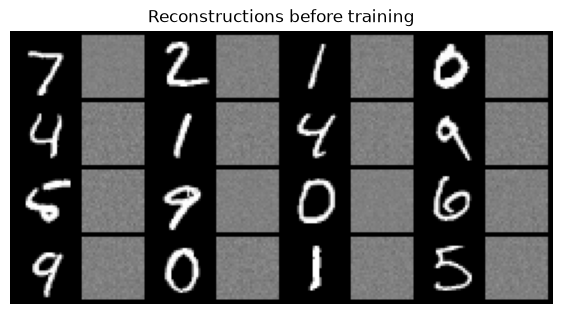

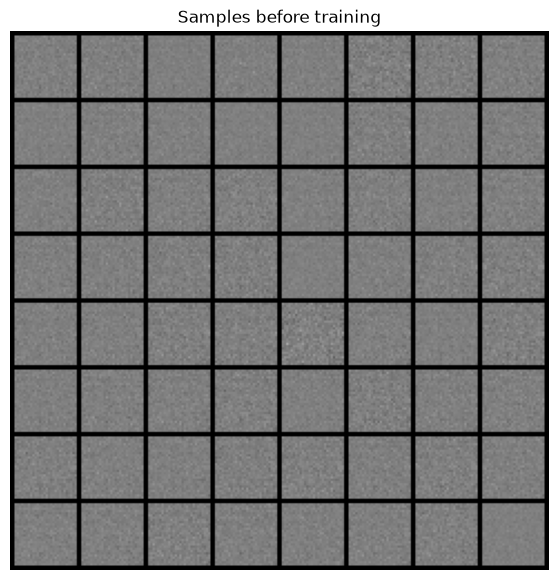

In [9]:
@torch.no_grad()
def reconstruct_images(hvae, images=fixed_test_images, title="Reconstructions", save_path=None):
    hvae.eval()
    outputs = hvae(images)
    reconstructions = torch.sigmoid(outputs["reconstruction_logits"])

    pairs = torch.empty(images.size(0) * 2, *images.shape[1:], device=images.device)
    pairs[0::2] = images
    pairs[1::2] = reconstructions

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(pairs.cpu().clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(pairs, title=title, nrow=8)


@torch.no_grad()
def sample_images(hvae, num_samples=64, title="Generated samples", save_path=None):
    hvae.eval()
    logits = hvae.sample(num_samples)
    images = torch.sigmoid(logits)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(images.cpu().clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(images, title=title, nrow=8)


def save_checkpoint(epoch, history):
    torch.save(
        {
            "epoch": epoch,
            "hvae_state_dict": hvae.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "config": {
                "image_channels": image_channels,
                "image_size": image_size,
                "hidden_dim": hidden_dim,
                "levels": levels,
                "latent_dims": latent_dims,
                "lower_latent_dim": lower_latent_dim,
                "top_latent_dim": top_latent_dim,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
            },
        },
        checkpoint_path,
    )


reconstruct_images(hvae, title="Reconstructions before training")
sample_images(hvae, title="Samples before training")

Before training, the model has no useful latent structure yet, so both reconstructions and samples should look like gray noise.

## 8. Hierarchical VAE Training Step

The training loop looks almost identical to the vanilla VAE, but the metrics now separate the two KL terms so we can see how each latent level is being used.

In [10]:
def run_epoch(hvae, data_loader, train=True):
    hvae.train(train)
    total_loss = 0.0
    total_reconstruction_loss = 0.0
    total_kl = [0.0] * hvae.levels
    total_images = 0

    for images, _ in data_loader:
        images = images.to(device, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)

        outputs = hvae(images)
        loss, reconstruction_loss, kl_terms = hierarchical_vae_loss(outputs, images)

        if train:
            loss.backward()
            optimizer.step()

        batch_size_seen = images.size(0)
        total_loss += loss.item()
        total_reconstruction_loss += reconstruction_loss.item()
        for level, kl in enumerate(kl_terms):
            total_kl[level] += kl.item()
        total_images += batch_size_seen

    metrics = {
        "loss": total_loss / total_images,
        "reconstruction_loss": total_reconstruction_loss / total_images,
    }
    for level, kl in enumerate(total_kl):
        metrics[f"z{level + 1}_kl"] = kl / total_images
    return metrics


def train_one_epoch(epoch, hvae, train_loader, test_loader):
    train_metrics = run_epoch(hvae, train_loader, train=True)
    with torch.no_grad():
        test_metrics = run_epoch(hvae, test_loader, train=False)

    metrics = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_reconstruction_loss": train_metrics["reconstruction_loss"],
        "test_loss": test_metrics["loss"],
        "test_reconstruction_loss": test_metrics["reconstruction_loss"],
    }
    for level in range(hvae.levels):
        metrics[f"train_z{level + 1}_kl"] = train_metrics[f"z{level + 1}_kl"]
        metrics[f"test_z{level + 1}_kl"] = test_metrics[f"z{level + 1}_kl"]
    return metrics

## 9. Train the Hierarchical VAE

Run this cell to train. Watch both KL terms: if one stays near zero for the whole run, that latent level may not be carrying much information.

Epoch 001/020 | train loss: 180.00 | train recon: 174.00 | train KL z1: 3.34 | train KL z2: 2.66 | test loss: 139.57
Epoch 002/020 | train loss: 130.98 | train recon: 118.49 | train KL z1: 4.99 | train KL z2: 7.50 | test loss: 124.22
Epoch 003/020 | train loss: 121.82 | train recon: 108.00 | train KL z1: 4.66 | train KL z2: 9.15 | test loss: 118.86
Epoch 004/020 | train loss: 117.27 | train recon: 102.67 | train KL z1: 5.06 | train KL z2: 9.54 | test loss: 115.11
Epoch 005/020 | train loss: 113.63 | train recon: 98.18 | train KL z1: 5.60 | train KL z2: 9.85 | test loss: 111.69


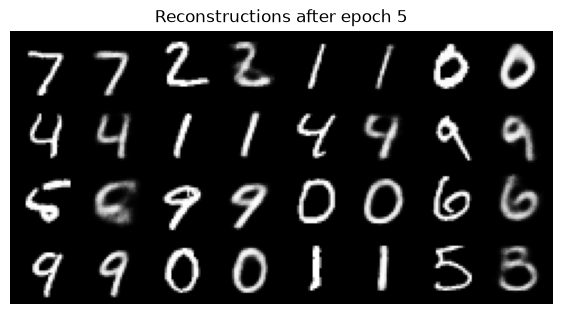

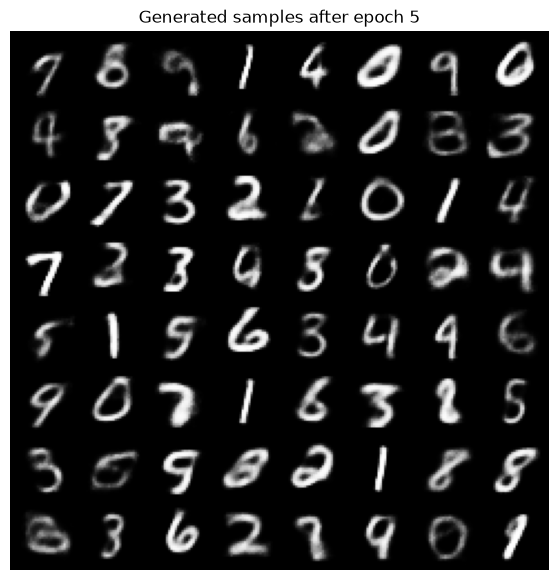

Epoch 006/020 | train loss: 110.63 | train recon: 94.38 | train KL z1: 6.18 | train KL z2: 10.07 | test loss: 109.41
Epoch 007/020 | train loss: 108.47 | train recon: 91.71 | train KL z1: 6.82 | train KL z2: 9.94 | test loss: 107.71
Epoch 008/020 | train loss: 106.97 | train recon: 89.87 | train KL z1: 7.33 | train KL z2: 9.77 | test loss: 106.64
Epoch 009/020 | train loss: 105.79 | train recon: 88.46 | train KL z1: 7.74 | train KL z2: 9.59 | test loss: 105.36
Epoch 010/020 | train loss: 104.82 | train recon: 87.29 | train KL z1: 8.14 | train KL z2: 9.39 | test loss: 104.65


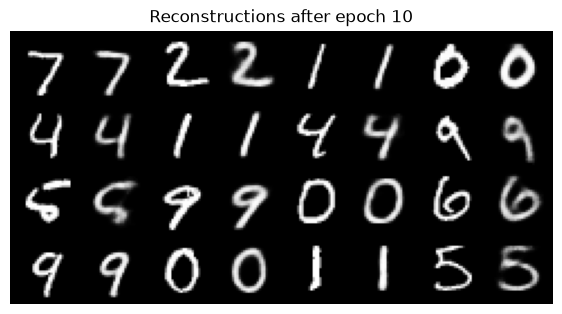

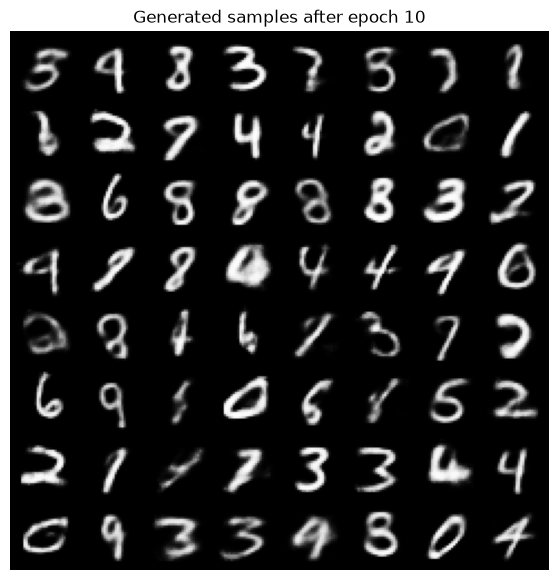

Epoch 011/020 | train loss: 104.05 | train recon: 86.31 | train KL z1: 8.59 | train KL z2: 9.14 | test loss: 104.24
Epoch 012/020 | train loss: 103.33 | train recon: 85.42 | train KL z1: 9.04 | train KL z2: 8.87 | test loss: 103.46
Epoch 013/020 | train loss: 102.64 | train recon: 84.58 | train KL z1: 9.46 | train KL z2: 8.60 | test loss: 102.98
Epoch 014/020 | train loss: 102.11 | train recon: 83.85 | train KL z1: 9.87 | train KL z2: 8.38 | test loss: 102.84
Epoch 015/020 | train loss: 101.56 | train recon: 83.16 | train KL z1: 10.21 | train KL z2: 8.19 | test loss: 102.21


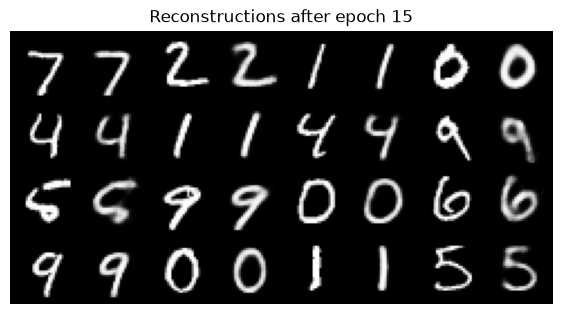

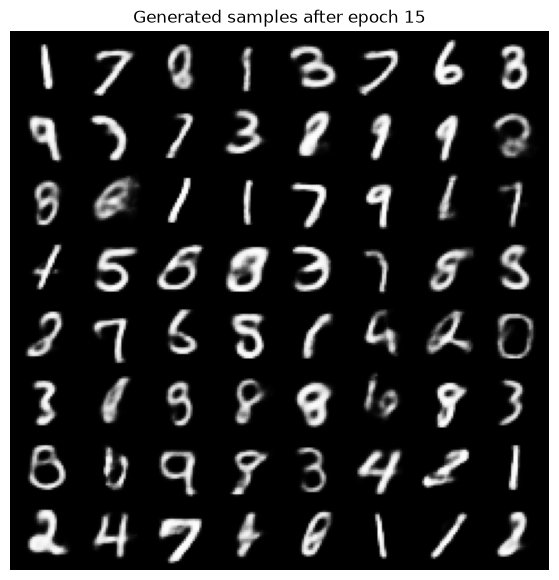

Epoch 016/020 | train loss: 101.06 | train recon: 82.54 | train KL z1: 10.52 | train KL z2: 8.00 | test loss: 101.59
Epoch 017/020 | train loss: 100.67 | train recon: 82.05 | train KL z1: 10.77 | train KL z2: 7.84 | test loss: 101.40
Epoch 018/020 | train loss: 100.37 | train recon: 81.62 | train KL z1: 11.02 | train KL z2: 7.73 | test loss: 100.88
Epoch 019/020 | train loss: 99.98 | train recon: 81.13 | train KL z1: 11.20 | train KL z2: 7.64 | test loss: 101.07
Epoch 020/020 | train loss: 99.66 | train recon: 80.77 | train KL z1: 11.34 | train KL z2: 7.55 | test loss: 100.89


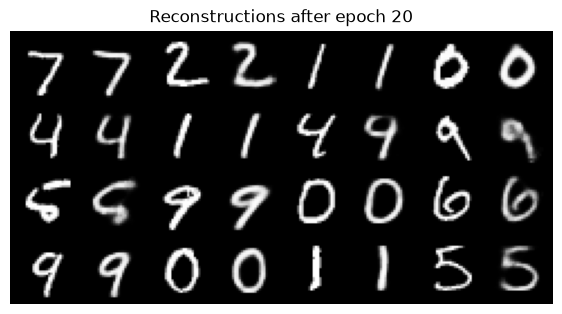

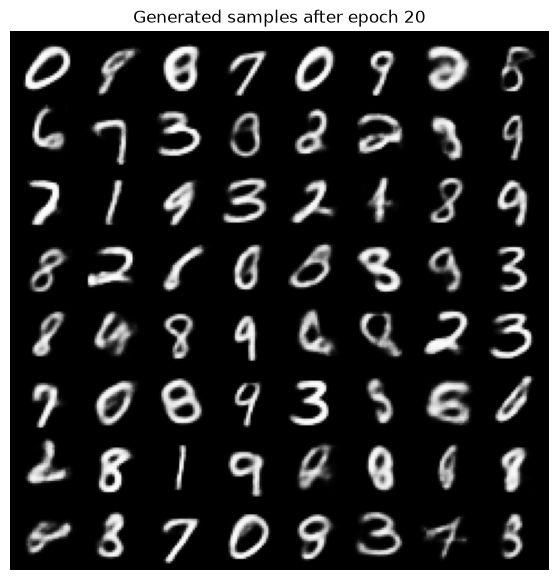

Saved latest checkpoint to: /home/nahuel/generative-networks/vae/outputs/mnist_hierarchical_vae/mnist_hierarchical_vae_checkpoint.pt


In [11]:
history = []

for epoch in range(1, epochs + 1):
    metrics = train_one_epoch(epoch, hvae, train_loader, test_loader)
    history.append(metrics)

    train_kl_text = " | ".join(
        f"train KL z{level + 1}: {metrics[f'train_z{level + 1}_kl']:.2f}"
        for level in range(hvae.levels)
    )
    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"train loss: {metrics['train_loss']:.2f} | "
        f"train recon: {metrics['train_reconstruction_loss']:.2f} | "
        f"{train_kl_text} | "
        f"test loss: {metrics['test_loss']:.2f}"
    )

    if epoch % sample_every_epochs == 0 or epoch == epochs:
        reconstruction_path = output_dir / f"reconstructions_epoch_{epoch:03d}.png"
        sample_path = output_dir / f"samples_epoch_{epoch:03d}.png"
        reconstruct_images(hvae, title=f"Reconstructions after epoch {epoch}", save_path=reconstruction_path)
        sample_images(hvae, title=f"Generated samples after epoch {epoch}", save_path=sample_path)

    save_checkpoint(epoch, history)

print(f"Saved latest checkpoint to: {checkpoint_path}")

## 10. Plot Training Curves

Plotting the KL terms separately helps diagnose whether the hierarchy is active. In small models, it is common for one level to dominate at first.

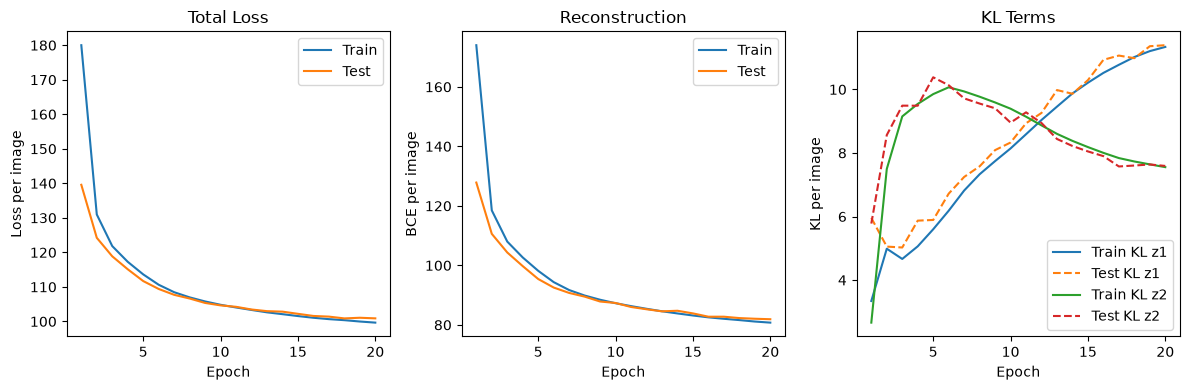

In [18]:
epochs_seen = [row["epoch"] for row in history]

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(epochs_seen, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Loss per image")
plt.legend()
plt.title("Total Loss")

plt.subplot(1, 3, 2)
plt.plot(epochs_seen, [row["train_reconstruction_loss"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_reconstruction_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("BCE per image")
plt.legend()
plt.title("Reconstruction")

plt.subplot(1, 3, 3)
for level in range(hvae.levels):
    plt.plot(epochs_seen, [row[f"train_z{level + 1}_kl"] for row in history], label=f"Train KL z{level + 1}")
    plt.plot(epochs_seen, [row[f"test_z{level + 1}_kl"] for row in history], linestyle="--", label=f"Test KL z{level + 1}")
plt.xlabel("Epoch")
plt.ylabel("KL per image")
plt.legend()
plt.title("KL Terms")

plt.tight_layout()
plt.show()

## 11. Reconstruct Test Digits

Each pair below shows an original test image followed by its reconstruction.

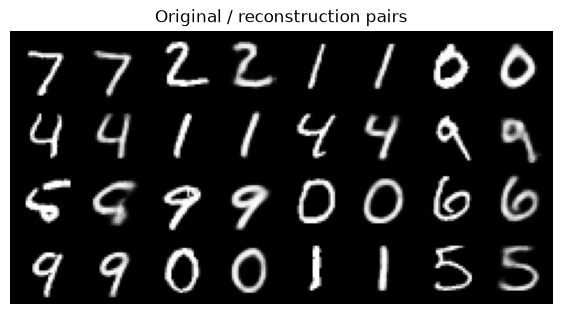

In [19]:
test_images, test_labels = next(iter(test_loader))
reconstruct_images(hvae, images=test_images[:16].to(device), title="Original / reconstruction pairs")

## 12. Generate New Digits

Sampling follows the generative hierarchy: first sample `z2`, then sample `z1` from `p(z1 | z2)`, then decode `z1`.

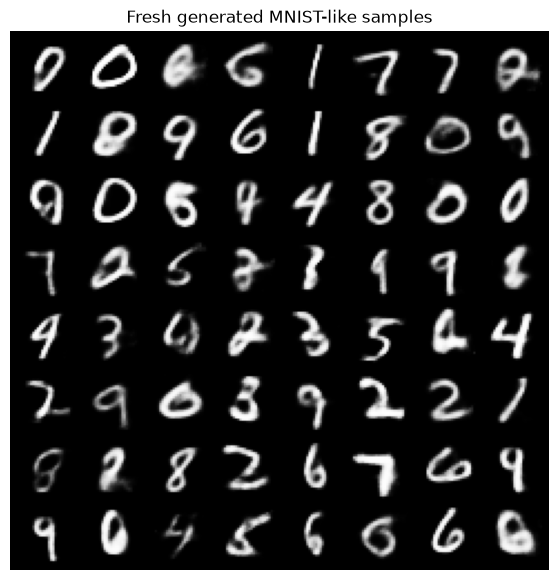

In [20]:
sample_images(hvae, num_samples=64, title="Fresh generated MNIST-like samples")

## 13. Interpolate the Top Latent Level

Here we encode two images, interpolate between their `z2` means, then decode through the learned conditional prior `p(z1 | z2)`. This highlights the higher-level part of the hierarchy.

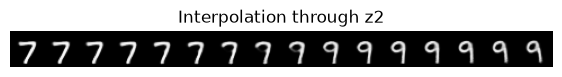

In [21]:
@torch.no_grad()
def interpolate_top_latent(hvae, images, start_index=0, end_index=1, steps=16):
    hvae.eval()
    images = images.to(device)
    _, mus, _ = hvae.encode(images)
    top_level = hvae.levels - 1

    top_start = mus[top_level][start_index:start_index + 1]
    top_end = mus[top_level][end_index:end_index + 1]
    weights = torch.linspace(0, 1, steps, device=device).view(steps, 1)
    latents = [None] * hvae.levels
    latents[top_level] = (1 - weights) * top_start + weights * top_end

    for level in reversed(range(top_level)):
        prior_mu, prior_logvar = hvae.conditional_prior(level, latents[level + 1])
        latents[level] = prior_mu

    logits = hvae.decode(latents[0])
    generated = torch.sigmoid(logits)
    show_image_grid(generated, title=f"Interpolation through z{top_level + 1}", nrow=steps)


test_images, test_labels = next(iter(test_loader))
interpolate_top_latent(hvae, test_images, start_index=0, end_index=7, steps=16)

## 14. Inspect Latent Usage

The average KL value for each level is a useful quick proxy for how much information that level carries. Larger values usually mean the posterior is moving farther from the prior and using that latent code more.

In [22]:
if history:
    latest = history[-1]
    for level in range(hvae.levels):
        print(f"Latest train KL z{level + 1}: {latest[f'train_z{level + 1}_kl']:.2f} nats per image")
else:
    print("Train the model first, then rerun this cell to inspect latent usage.")

Latest train KL z1: 11.34 nats per image
Latest train KL z2: 7.55 nats per image


## 15. Loading a Saved Checkpoint

Use this cell later if you restart the kernel and want to resume from the latest saved model.

In [17]:
# checkpoint = torch.load(checkpoint_path, map_location=device)
# hvae.load_state_dict(checkpoint["hvae_state_dict"])
# optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# history = checkpoint["history"]
# print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")

## 16. Things to Try

- Compare the generated samples against the basic VAE notebook after the same number of epochs.
- Change `levels`, `lower_latent_dim`, and `top_latent_dim` to see which latent levels carry more information.
- Add a `beta_z1` and `beta_z2` multiplier to control the two KL terms separately.
- Replace the fully connected encoder and decoder with convolutional networks.
- Decode from each conditional prior mean during sampling instead of sampled lower latents to compare deterministic and stochastic generation.

## Troubleshooting

- If one KL term stays at zero, that latent level may be inactive. Try reducing the other latent dimension or adding KL warm-up.
- If samples are much worse than reconstructions, train longer or use a convolutional decoder.
- If you run out of GPU memory, lower `batch_size`.